# Anushka Borekar
## B B3 37
## ML LAB 9

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score)
from scipy.cluster.hierarchy import linkage, dendrogram
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8,5)
df=pd.read_csv("Wholesale customers data.csv")

In [3]:
X = df.drop(columns=["Channel", "Region"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)
print(X_scaled_df.head())

      Fresh      Milk   Grocery    Frozen  Detergents_Paper  Delicassen
0  0.052933  0.523568 -0.041115 -0.589367         -0.043569   -0.066339
1 -0.391302  0.544458  0.170318 -0.270136          0.086407    0.089151
2 -0.447029  0.408538 -0.028157 -0.137536          0.133232    2.243293
3  0.100111 -0.624020 -0.392977  0.687144         -0.498588    0.093411
4  0.840239 -0.052396 -0.079356  0.173859         -0.231918    1.299347


In [4]:
print(X_scaled_df.mean().round(3))

Fresh              -0.0
Milk                0.0
Grocery            -0.0
Frozen              0.0
Detergents_Paper    0.0
Delicassen         -0.0
dtype: float64


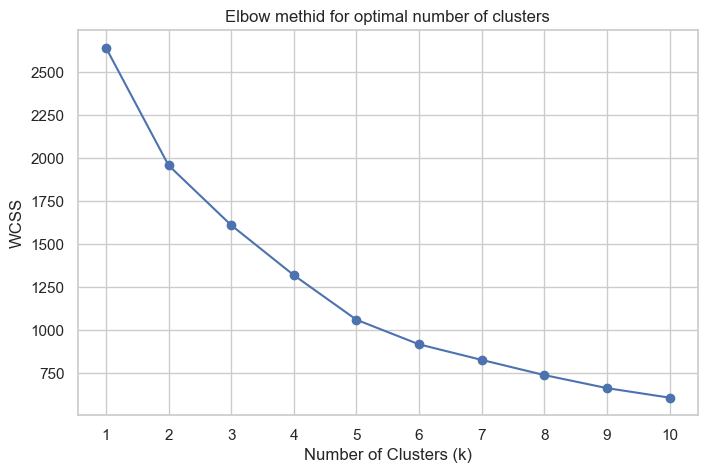

In [6]:
wcss = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
plt.figure(figsize=(8,5))
plt.plot(k_values, wcss, marker='o')
plt.title("Elbow methid for optimal number of clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [11]:
silhouette_values = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_values.append(score)

silhouette_table = pd.DataFrame({
    "Number of Clusters": list(range(2, 11)),
    "Silhouette Score": silhouette_values
})
display(silhouette_table.round(3))

,Number of Clusters,Silhouette Score
0,2,0.547
1,3,0.548
2,4,0.348
3,5,0.369
4,6,0.378
5,7,0.334
6,8,0.320
7,9,0.309
8,10,0.311


In [12]:
suggested_k = int(
    silhouette_table.loc[
        silhouette_table["Silhouette Score"].idxmax(),
        "Number of Clusters"
    ]
)

print("Suggested number of clusters:", suggested_k)

Suggested number of clusters: 3


In [13]:
k = suggested_k

kmeans_model = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_scaled)

In [15]:
df_kmeans = df.copy()

df_kmeans["KMeans_Cluster"] = kmeans_labels

print("K-Means clustering completed")
print("\nNumber of customers in each cluster:")
print(df_kmeans["KMeans_Cluster"].value_counts().sort_index())

print("\nSample records with cluster labels:")
display(df_kmeans.head())

K-Means clustering completed

Number of customers in each cluster:
KMeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64

Sample records with cluster labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


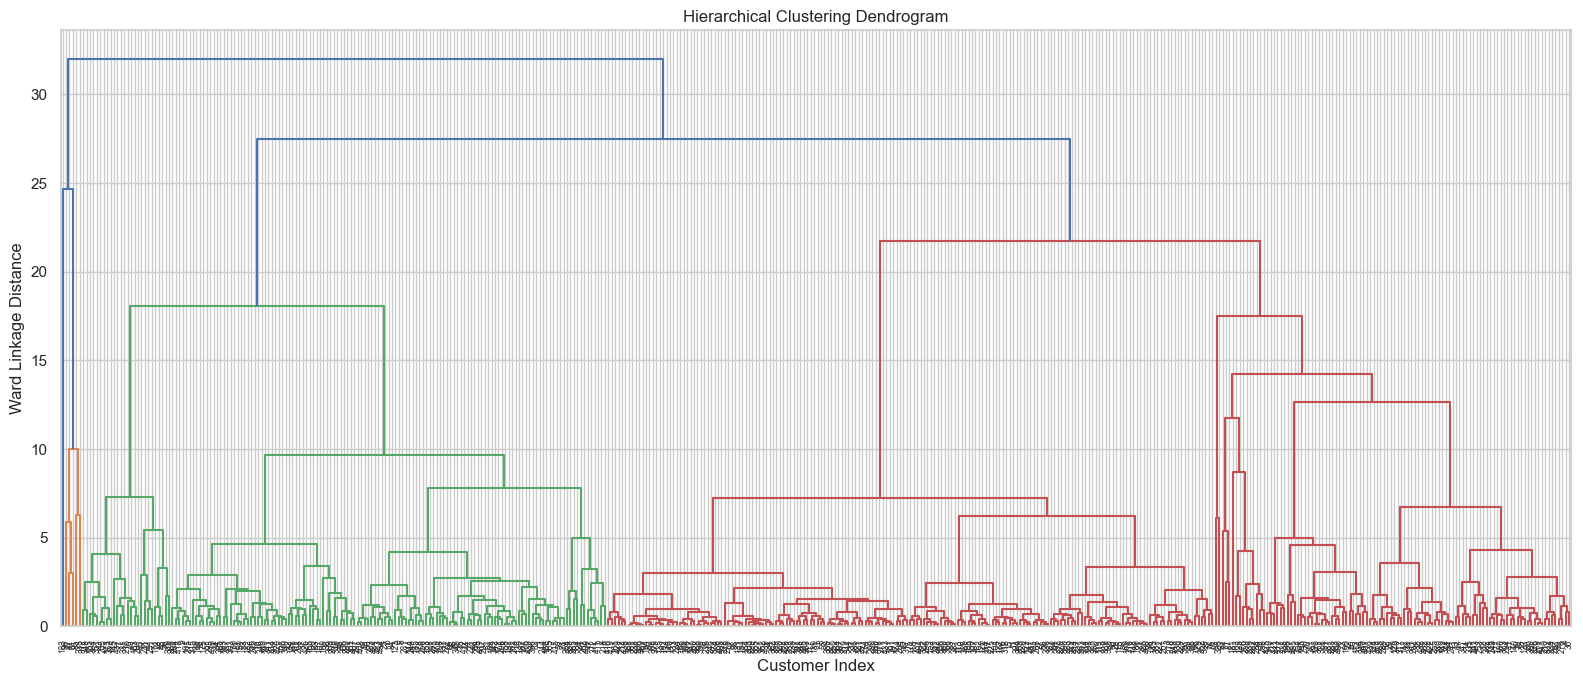

In [17]:
Z = linkage(X_scaled, method="ward", metric="euclidean")

plt.figure(figsize=(16, 7))
dendrogram(
    Z,
    leaf_rotation=90,
    leaf_font_size=6
)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customer Index")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

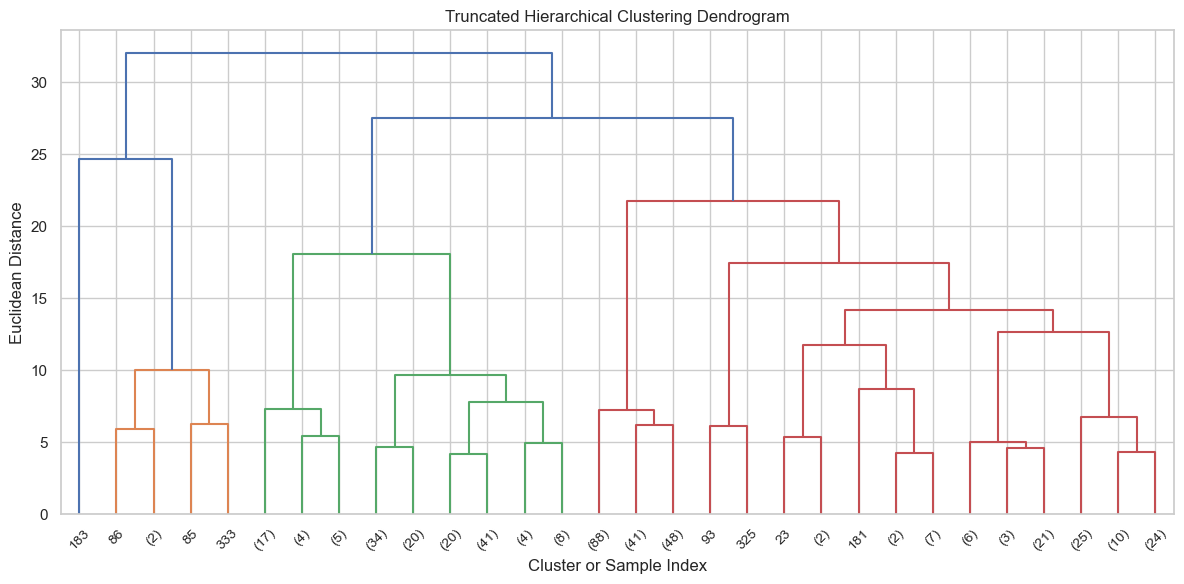

In [18]:
plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=45
)

plt.title("Truncated Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster or Sample Index")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

In [21]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print(
    "Variance explained by the two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1]
})

pca_df["KMeans_Cluster"] = kmeans_labels

display(pca_df.head())

Variance explained by the two PCA components: 72.46 %


,PC1,PC2,KMeans_Cluster
0,0.193291,-0.305100,1
1,0.434420,-0.328413,1
2,0.811143,0.815096,1
3,-0.778648,0.652754,1
4,0.166287,1.271434,1


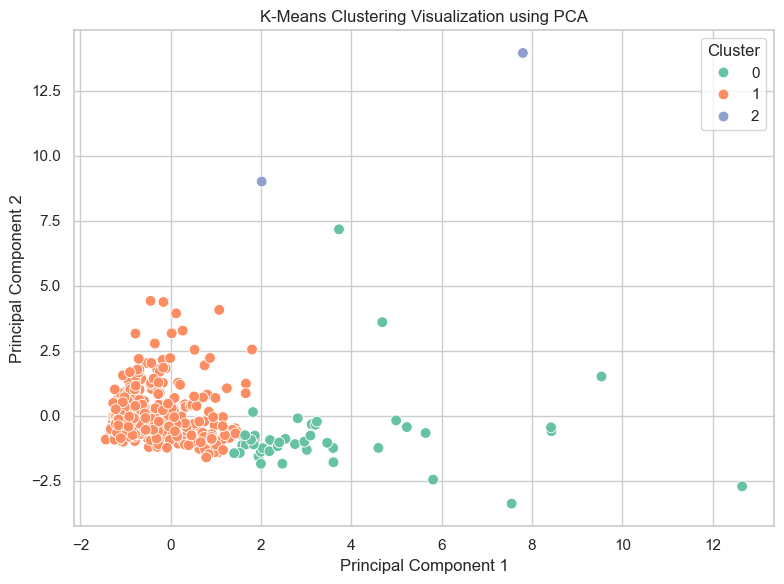

In [22]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="KMeans_Cluster",
    palette="Set2",
    s=60
)

plt.title("K-Means Clustering Visualization using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [25]:
def evaluate_clustering(X_data, labels, model_name):
    return {
        "Algorithm": model_name,
        "Number of Clusters": len(np.unique(labels)),
        "Silhouette Score": silhouette_score(X_data, labels)}

In [29]:
hierarchical_model = AgglomerativeClustering(
    n_clusters=suggested_k,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

In [30]:
comparison = pd.DataFrame([
    evaluate_clustering(X_scaled, kmeans_labels, "K-Means"),
    evaluate_clustering(
        X_scaled,
        hierarchical_labels,
        "Hierarchical Clustering"
    )
])

display(comparison.round(4))

,Algorithm,Number of Clusters,Silhouette Score
0,K-Means,3,0.5483
1,Hierarchical Clustering,3,0.2646


NameError: name 'kmeans_sizes' is not defined